# From ENCODE sample IDs to AlphaGenome expression outputs

This notebook explains the matching step before prediction. It works offline with
bundled human and mouse metadata snapshots; it never reads an API key or requests
predictions. Export fresh metadata with the README commands when changing model/client versions.

**Three different units**

- An experimental **track/sample ID** (`ENCFF…` or `ENCSR…`) identifies a file or experiment.
- An **ontology ID** (`CL:…` or `UBERON:…`) describes a cell type or tissue.
- An AlphaGenome RNA-seq output **name** combines ontology and assay, e.g.
  `UBERON:0006631 total RNA-seq`. We group measurements by this ontology–assay name.

An ontology may occur in more than one assay. Output metadata may also contain
separate `+`, `-`, or unstranded `.` rows for a name. Therefore counts of samples,
ontology IDs, names, and strand-level output rows are not interchangeable.

Reference discussion: https://chatgpt.com/s/cx_6ae1de5534b08191bcffd522d7793661
The counts below are recomputed from the files, rather than copied from that discussion.


In [1]:
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

ROOT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
            if (p / 'scripts/prepare_expression_mapping.py').exists())
DATA = ROOT / 'benchmarks/expression/data'
OUTPUT = ROOT / 'results/ontology_analysis'
OUTPUT.mkdir(parents=True, exist_ok=True)

def read_inputs(organism):
    suffix = '_mouse' if organism == 'mouse' else ''
    samples = pd.read_csv(DATA / f'qnorm_alphagenome_ontology_map{suffix}.csv', dtype=str).fillna('')
    metadata = pd.read_csv(DATA / f'alphagenome_{organism}_rna_seq_metadata.csv', dtype=str).fillna('')
    samples['ontology_name'] = samples.ontology_curie.str.strip() + ' ' + samples.assay.str.strip()
    return samples, metadata

inputs = {organism: read_inputs(organism) for organism in ['human', 'mouse']}
print('Repository:', ROOT)


Repository: /media/eternus1/nfs/projects/dpanchenko/BenchAG


## 1. See the connection for individual samples

The ENCODE resolver reads a file or experiment record and obtains its biosample
ontology and assay. If these fields are stored on the parent experiment, it follows
that relationship. It then requires an exact ontology-and-assay match in the
AlphaGenome metadata. Matching uses the canonical output name: the metadata
`Assay title` can be broader than the assay encoded in that name. A match describes the same biological measurement context;
it does not prove the same experimental file was used by both datasets.


In [2]:
samples, metadata = inputs['human']
print(samples[['id', 'query_accession', 'ontology_curie', 'biosample_name', 'assay', 'ontology_name']].head(8).to_string(index=False))
print('\nOne ontology can have several assay names:')
assays_per_ontology = metadata.groupby('ontology_curie')['Assay title'].nunique()
example_ids = assays_per_ontology[assays_per_ontology > 1].index[:2]
print(metadata[metadata.ontology_curie.isin(example_ids)][['ontology_curie', 'Assay title', 'name']].drop_duplicates().to_string(index=False))


         id query_accession ontology_curie                                         biosample_name              assay                  ontology_name
ENCFF035CWS     ENCFF035CWS UBERON:0001159                                          sigmoid colon      total RNA-seq   UBERON:0001159 total RNA-seq
ENCFF329ENM     ENCFF329ENM UBERON:0001157                                       transverse colon      total RNA-seq   UBERON:0001157 total RNA-seq
ENCFF761SPP     ENCFF761SPP    EFO:0001187                                                  HepG2 polyA plus RNA-seq EFO:0001187 polyA plus RNA-seq
ENCFF731CJY     ENCFF731CJY     CL:2000040                 bladder microvascular endothelial cell      total RNA-seq       CL:2000040 total RNA-seq
ENCFF242NRP     ENCFF242NRP     CL:0002328                              bronchial epithelial cell      total RNA-seq       CL:0002328 total RNA-seq
ENCFF465EDA     ENCFF465EDA     CL:2000010                   dermis blood vessel endothelial cell      total RNA

## 2. Count the shared ontology–assay names

Sets can be intersected only when their elements have the same meaning. We intersect
**ontology–assay names** on both sides, then count how many experimental samples and
AlphaGenome output rows belong to those shared names. We do not intersect an ENCODE
accession with an AlphaGenome strand-level row.

The diagrams below are schematic; circle areas are not proportional to counts.


In [3]:
rows = []
shared_names = {}
for organism, (samples, metadata) in inputs.items():
    resolved = samples[(samples.ontology_curie != '') & (samples.assay != '')]
    sample_names = set(resolved.ontology_name)
    ag_names = set(metadata.name)
    shared = sample_names & ag_names
    shared_names[organism] = shared
    matched_samples = resolved[resolved.ontology_name.isin(shared)]
    matched_metadata = metadata[metadata.name.isin(shared)]
    rows.append(dict(organism=organism,
        experimental_tracks=len(samples), experimental_names=len(sample_names),
        ag_strand_level_rows=len(metadata), ag_names=len(ag_names),
        ag_unique_ontologies=metadata.ontology_curie.nunique(),
        shared_names=len(shared), experimental_tracks_in_shared_names=len(matched_samples),
        ag_rows_in_shared_names=len(matched_metadata), shared_unique_ontologies=matched_samples.ontology_curie.nunique()))
summary = pd.DataFrame(rows).set_index('organism')
print(summary.T.to_string())
summary.to_csv(OUTPUT / 'ontology_overlap_summary.csv')


organism                             human  mouse
experimental_tracks                    815    243
experimental_names                     302     69
ag_strand_level_rows                   667    173
ag_names                               371     90
ag_unique_ontologies                   285     75
shared_names                           285     68
experimental_tracks_in_shared_names    770    241
ag_rows_in_shared_names                552    135
shared_unique_ontologies               240     55


For the reference snapshot, human has 815 experimental tracks in 302 names;
AlphaGenome has 667 strand-level rows in 371 names (285 unique ontology IDs).
Their intersection is **285 names**, containing **770 experimental tracks** and
**552 AlphaGenome rows**, with **240 unique ontology IDs**.

Mouse has 243 experimental tracks in 69 names, and 173 AlphaGenome rows in 90 names
(75 unique ontology IDs). Its intersection is **68 names**, containing **241 experimental
tracks** and **135 AlphaGenome rows**, with **55 unique ontology IDs**.

These statements describe this metadata snapshot. New data or client/model changes
can change the counts; use the computed table above for your run.


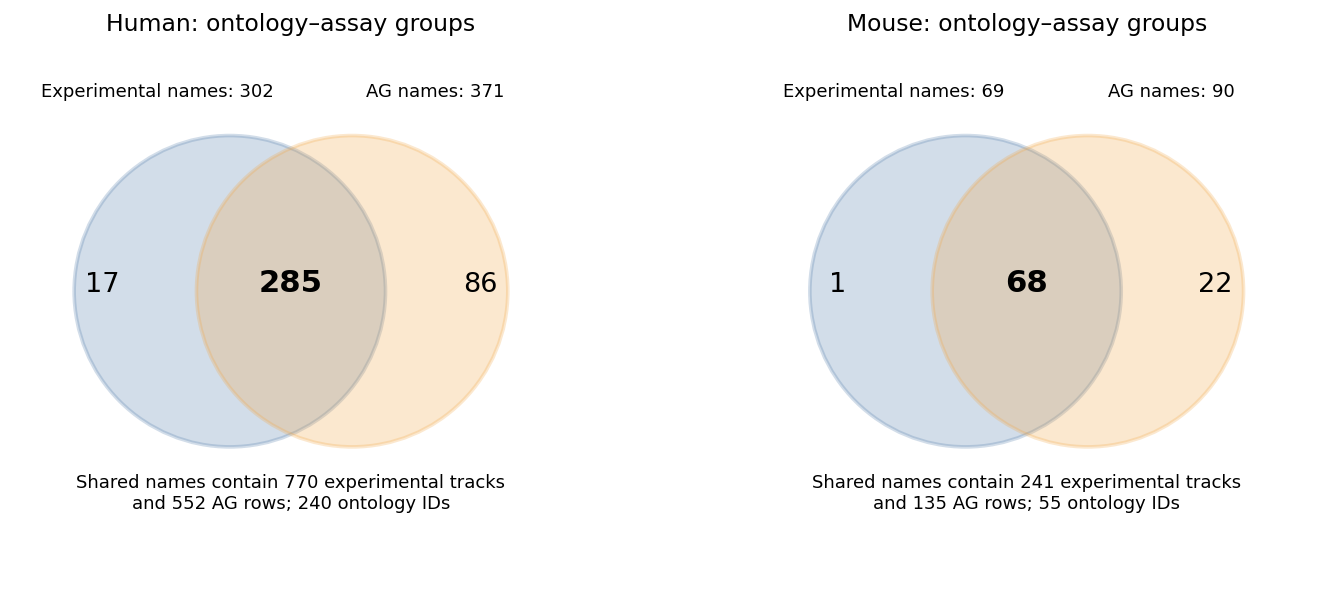

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, organism in zip(axes, ['human', 'mouse']):
    row = summary.loc[organism]
    left, right, overlap = int(row.experimental_names), int(row.ag_names), int(row.shared_names)
    for center, color in [((0.39, 0.55), '#4C78A8'), ((0.61, 0.55), '#F2A541')]:
        ax.add_patch(Circle(center, 0.28, facecolor=color, alpha=0.25, edgecolor=color, linewidth=2))
    ax.text(0.16, 0.55, str(left-overlap), ha='center', fontsize=15)
    ax.text(0.50, 0.55, str(overlap), ha='center', fontsize=17, fontweight='bold')
    ax.text(0.84, 0.55, str(right-overlap), ha='center', fontsize=15)
    ax.text(0.26, 0.90, f'Experimental names: {left}', ha='center', fontsize=10)
    ax.text(0.76, 0.90, f'AG names: {right}', ha='center', fontsize=10)
    ax.text(0.5, 0.16, f'Shared names contain {int(row.experimental_tracks_in_shared_names)} experimental tracks\nand {int(row.ag_rows_in_shared_names)} AG rows; {int(row.shared_unique_ontologies)} ontology IDs', ha='center', fontsize=10)
    ax.set_title(organism.capitalize() + ': ontology–assay groups', fontsize=13)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect('equal'); ax.axis('off')
fig.tight_layout()
fig.savefig(OUTPUT / 'ontology_group_overlap.png', dpi=160, bbox_inches='tight')
plt.show()


## 3. Inspect rows outside the shared groups and strand availability

A human track-level Venn with “815” and “667” would mix different units. In particular,
“552 AG rows in shared groups” is not an exact accession overlap. We show only the
name-level Venn above. Exact-source matching is a separate audit.

The historical prediction runner selects the gene's `+` or `-` strand. Metadata rows
with `.` are unstranded and are not selected by that rule. Thus a shared name is not
necessarily a usable prediction column. Keep requested-name counts separate from
finite-output counts; do not replace missing outputs with zeros.


In [5]:
for organism, (samples, metadata) in inputs.items():
    shared = shared_names[organism]
    selected = metadata[metadata.name.isin(shared)]
    outside = metadata[~metadata.name.isin(shared)]
    print('\n' + organism.upper())
    print('Shared output rows by strand:', selected.groupby('strand').size().to_dict())
    print('Shared names by strand:', selected.groupby('strand')['name'].nunique().to_dict())
    print('Rows outside shared groups by data source:', outside.groupby('data_source').size().to_dict())



HUMAN
Shared output rows by strand: {'+': 242, '-': 242, '.': 68}
Shared names by strand: {'+': 242, '-': 242, '.': 68}
Rows outside shared groups by data source: {'encode': 61, 'gtex': 54}

MOUSE
Shared output rows by strand: {'+': 55, '-': 55, '.': 25}
Shared names by strand: {'+': 55, '-': 55, '.': 25}
Rows outside shared groups by data source: {'encode': 38}


## 4. Understand the JSON mappings

`track_to_first_id.json` gives one representative sample label per AlphaGenome name.
`track_to_all_ids.json` retains all experimental samples in that group. The former is
used to select and label outputs in the historical runner; the latter defines which
measured samples are averaged for the ground-truth comparison. Our public prediction
command writes the AlphaGenome ontology–assay name as the output column header.

For comparison, transform each experimental sample as specified (the notebook uses
`log2(x+1)`), then average the transformed samples within the group. Do not take the
representative sample alone as the group ground truth. Do not average different assays
just because they share the same ontology ID.


In [6]:
for organism in ['human', 'mouse']:
    tag = 'mouse_' if organism == 'mouse' else ''
    first_path = DATA / f'alphagenome_track_to_qnorm_id_{tag}first.json'
    all_path = DATA / ('alphagenome_track_to_qnorm_ids_mouse_all.json' if organism == 'mouse' else 'alphagenome_track_to_qnorm_ids_all.json')
    first = json.loads(first_path.read_text())
    all_ids = json.loads(all_path.read_text())
    assert set(first) == set(all_ids) == shared_names[organism]
    assert all(first[name] in all_ids[name] for name in first)
    example = next((name for name in all_ids if len(all_ids[name]) > 1), next(iter(all_ids)))
    print(organism, example, '\n  representative:', first[example], '\n  all experimental IDs:', all_ids[example])

example_values = np.array([1., 15.])
print('\nExample only: two samples in one group:', example_values)
print('Mean log2(x+1):', np.log2(example_values + 1).mean())
print('log2(mean(x)+1) is a different calculation:', np.log2(example_values.mean() + 1))


human CL:0000047 polyA plus RNA-seq 
  representative: ENCFF572SPV 
  all experimental IDs: ['ENCFF572SPV', 'ENCFF958PFC']
mouse CL:0000037 total RNA-seq 
  representative: ENCFF995CGM 
  all experimental IDs: ['ENCFF505YKR', 'ENCFF995CGM']

Example only: two samples in one group: [ 1. 15.]
Mean log2(x+1): 2.5
log2(mean(x)+1) is a different calculation: 3.169925001442312


## 5. Build mappings for your own samples

From the BenchAG root, after setting `ALPHAGENOME_API_KEY`:

```bash
python scripts/prepare_expression_mapping.py --samples inputs/samples.txt --organism human --out inputs/human_mapping
```

Use `--organism mouse` for mouse. Review `sample_matching.csv` before continuing.
To reproduce the bundled reference matching without network calls:

```bash
python scripts/prepare_expression_mapping.py --ontology-map benchmarks/expression/data/qnorm_alphagenome_ontology_map.csv --metadata benchmarks/expression/data/alphagenome_human_rna_seq_metadata.csv --organism human --out results/reference_human_mapping
```

Predict with `scripts/predict_expression.py`, then compare with `scripts/compare_expression.py`.
See the expression README for the minimal input schemas and full commands.


In [7]:
sources = sorted(DATA.glob('alphagenome_*rna_seq_metadata.csv')) + sorted(DATA.glob('qnorm_alphagenome_ontology_map*.csv'))
manifest = {str(path.relative_to(ROOT)): hashlib.sha256(path.read_bytes()).hexdigest() for path in sources}
(OUTPUT / 'source_sha256.json').write_text(json.dumps(manifest, indent=2) + '\n')
print('Summary, plot and source hashes saved in:', OUTPUT)


Summary, plot and source hashes saved in: /media/eternus1/nfs/projects/dpanchenko/BenchAG/results/ontology_analysis
